# Trabalho Prático II — Metodologia Box-Jenkins e seleção do modelo ARIMA(p, d, q)

**Disciplina:** Séries Temporais e Aprendizagem Supervisionada II<br>
**Professor:** Gildo Leonel<br>
**Autoria:** Sophia Cristine Soares Mello<br>
**Data:** outubro de 2026

Este notebook continua o Trabalho I (`trabalho1_series_temporais.ipynb`, na raiz do repositório) e usa a mesma série: o índice de volume de vendas do varejo da PMC/IBGE. Agora a ideia é escolher os parâmetros $(p, d, q)$ de um modelo ARIMA de forma justificada, seguindo o ciclo de Box-Jenkins:

1. **Identificação:** propor candidatos a partir do ADF e dos correlogramas;
2. **Estimação:** ajustar os candidatos e uma grade de modelos por máxima verossimilhança, comparando AIC e BIC;
3. **Verificação:** olhar os resíduos e, se for preciso, voltar para a identificação.

O foco do enunciado são as duas primeiras fases. No final eu faço uma volta rápida pela terceira, porque foi ela que mostrou o que ainda faltava no modelo.




## 0. Recapitulação do Trabalho I

A série é o índice de volume de vendas no comércio varejista do Brasil, da Pesquisa Mensal de Comércio do IBGE ([tabela SIDRA 8880](https://sidra.ibge.gov.br/tabela/8880), variável 7169, base 2022 = 100, sem ajuste sazonal), com 319 meses entre janeiro de 2000 e julho de 2026. Ela mede a quantidade vendida pelo varejo, então funciona como um termômetro do consumo das famílias. Escolhi a versão sem ajuste sazonal no Trabalho I justamente para estudar a sazonalidade, que é bem forte: dezembro vende cerca de 30% acima da tendência. Aqui uso a mesma cópia dos dados (`data/pmc_varejo_volume_ibge.csv`), para os números baterem com os do Trabalho I.

Do Trabalho I, trago três conclusões:

- a sazonalidade é multiplicativa, por isso trabalho com $\log y_t$;
- pelo ADF, a série só fica estacionária com uma diferença simples e uma diferença sazonal (a tabela abaixo refaz os testes);
- a FAC e a FACP da série transformada $w_t = \nabla\nabla_{12}\log y_t$ tinham picos negativos nos lags 1 e 12. Na época eu comentei que isso lembrava o modelo SARIMA$(0,1,1)(0,1,1)_{12}$ de Box e Jenkins, e aqui vou poder testar essa ideia.

In [1]:
import itertools
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels
from cycler import cycler
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, adfuller, pacf

# statsmodels >= 0.15 avisa que adfuller vai mudar o tipo de retorno; sigo com a tupla, como no Trabalho I
warnings.filterwarnings("ignore", message=".*currently returns a plain tuple.*", category=FutureWarning)

# mesmo estilo de gráficos do Trabalho I
AZUL, LARANJA = "#2a78d6", "#eb6834"
CINZA_MARCA = "#c3c2b7"
TINTA, TINTA_2, TINTA_SUAVE = "#0b0b0b", "#52514e", "#898781"
GRADE, FUNDO = "#e1e0d9", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "figure.dpi": 110, "font.size": 10,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "axes.prop_cycle": cycler(color=[AZUL, LARANJA]),
    "axes.edgecolor": CINZA_MARCA, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRADE, "grid.linewidth": 0.7, "grid.linestyle": "-",
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlecolor": TINTA, "axes.labelcolor": TINTA_2, "axes.labelsize": 10,
    "xtick.color": CINZA_MARCA, "ytick.color": CINZA_MARCA,
    "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "lines.linewidth": 1.6, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "legend.fontsize": 9, "legend.labelcolor": TINTA_2,
})


def estilizar_correlograma(ax, banda):
    """Mesmo ajuste visual do Trabalho I para os gráficos do plot_acf/plot_pacf."""
    for colecao in ax.collections:
        if isinstance(colecao, PolyCollection):  # faixa de confiança do statsmodels
            colecao.set_facecolor(AZUL)
            colecao.set_alpha(0.10)
            colecao.set_edgecolor("none")
    for linha in ax.get_lines():
        ydata = np.asarray(linha.get_ydata(), dtype=float)
        if len(ydata) == 2 and np.allclose(ydata, 0):  # linha do zero
            linha.set_color(CINZA_MARCA)
            linha.set_linewidth(0.8)
    for limite in (banda, -banda):
        ax.axhline(limite, color=TINTA_SUAVE, lw=0.7)


print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| statsmodels", statsmodels.__version__)

numpy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2 | statsmodels 0.15.0


In [2]:
# mesma cópia dos dados do Trabalho I (este notebook fica dentro da pasta trabalho2/)
dados = pd.read_csv("../data/pmc_varejo_volume_ibge.csv", parse_dates=["data"])
vendas = dados.set_index("data")["indice_volume"].asfreq("MS")
log_vendas = np.log(vendas)

# separo o teste logo no começo para não usá-lo em nada, nem na identificação.
# São os últimos 36 meses, o mesmo corte do bônus do Trabalho I.
H = 36
treino, teste = log_vendas.iloc[:-H], log_vendas.iloc[-H:]

print(f"série completa: {vendas.index[0]:%m/%Y} a {vendas.index[-1]:%m/%Y} (n = {len(vendas)})")
print(f"treino: {treino.index[0]:%m/%Y} a {treino.index[-1]:%m/%Y} (n = {len(treino)})")
print(f"teste:  {teste.index[0]:%m/%Y} a {teste.index[-1]:%m/%Y} (n = {len(teste)}, {H / len(vendas):.1%} da série)")

série completa: 01/2000 a 07/2026 (n = 319)
treino: 01/2000 a 07/2023 (n = 283)
teste:  08/2023 a 07/2026 (n = 36, 11.3% da série)


In [3]:
# recapitulação do ADF do Trabalho I (série toda) e o mesmo teste só no treino
recap = []
for nome, serie_toda, serie_treino in [
    ("original", vendas, np.exp(treino)),
    ("log(y)", log_vendas, treino),
    ("∇ log(y)", log_vendas.diff(), treino.diff()),
    ("∇12 log(y)", log_vendas.diff(12), treino.diff(12)),
    ("∇∇12 log(y)", log_vendas.diff(12).diff(), treino.diff(12).diff()),
]:
    estatistica, p_valor = adfuller(serie_toda.dropna(), autolag="AIC")[:2]
    p_treino = adfuller(serie_treino.dropna(), autolag="AIC")[1]
    recap.append({"série": nome, "estatística ADF (série toda)": estatistica,
                  "p-valor (série toda)": p_valor, "p-valor (só treino)": p_treino})
pd.DataFrame(recap).set_index("série").round(4)

,estatística ADF (série toda),p-valor (série toda),p-valor (só treino)
série,,,
original,-1.1779,0.6830,0.6953
log(y),-1.5299,0.5187,0.5895
∇ log(y),-3.0882,0.0274,0.0207
∇12 log(y),-2.9353,0.0414,0.0816
∇∇12 log(y),-6.5177,0.0000,0.0000


Na série toda, os resultados são os mesmos do Trabalho I. Só com o treino as conclusões não mudam, e um detalhe fica até mais claro: a diferença sazonal sozinha ($\nabla_{12}$) não passa no teste (p = 0,082). Ou seja, as duas diferenças são necessárias mesmo.

## Item 1 — Identificação: propondo os candidatos (p, d, q)

### 1.1 Definição de d

A tabela confirma o que eu tinha visto no Trabalho I. A série original (p = 0,683) e o log (p = 0,519) têm raiz unitária. Com uma diferença simples, o ADF já rejeita a raiz unitária (p = 0,027), e se eu olhasse só para o p-valor pararia aí. O problema é que, no Trabalho I, a FAC de $\nabla\log y_t$ ainda tinha autocorrelações de 0,93, 0,88 e 0,85 nos lags 12, 24 e 36, ou seja, sobrava uma raiz unitária sazonal que o ADF não testa. Por isso apliquei também a diferença sazonal, e com as duas juntas o teste rejeita a raiz unitária com folga (estatística de −6,52, p < 0,0001).

Então fico com **d = 1**, que é o número de diferenças simples do ARIMA. A diferença sazonal ($D = 1$, período 12) entra como um passo fixo que já vinha do Trabalho I. No `statsmodels` isso é `order=(p, 1, q)` junto com `seasonal_order=(0, 1, 0, 12)`, e esse segundo argumento só aplica $\nabla_{12}$, sem acrescentar nenhum parâmetro. O modelo que vou estimar fica

$$\phi(L)\,(1-L)\,(1-L^{12})\,\log y_t = \theta(L)\,\varepsilon_t,$$

que é a mesma coisa que ajustar um ARMA(p, q) em $w_t = \nabla\nabla_{12}\log y_t$. Não incluí a constante $c$ porque, depois das duas diferenças, a média de $w_t$ no treino é praticamente zero (0,00002). Além disso, uma constante nesse modelo viraria uma tendência quadrática no nível da série, o que não faz sentido aqui.

### 1.2 Releitura da FAC e da FACP

Como agora existe um conjunto de teste, refiz os correlogramas só com os dados de treino, para que nem a identificação use informação do teste. O desenho ficou praticamente igual ao do Trabalho I.

w_t no treino: n = 270 | média = 0.00002 | banda = ±1.96/√n = ±0.119


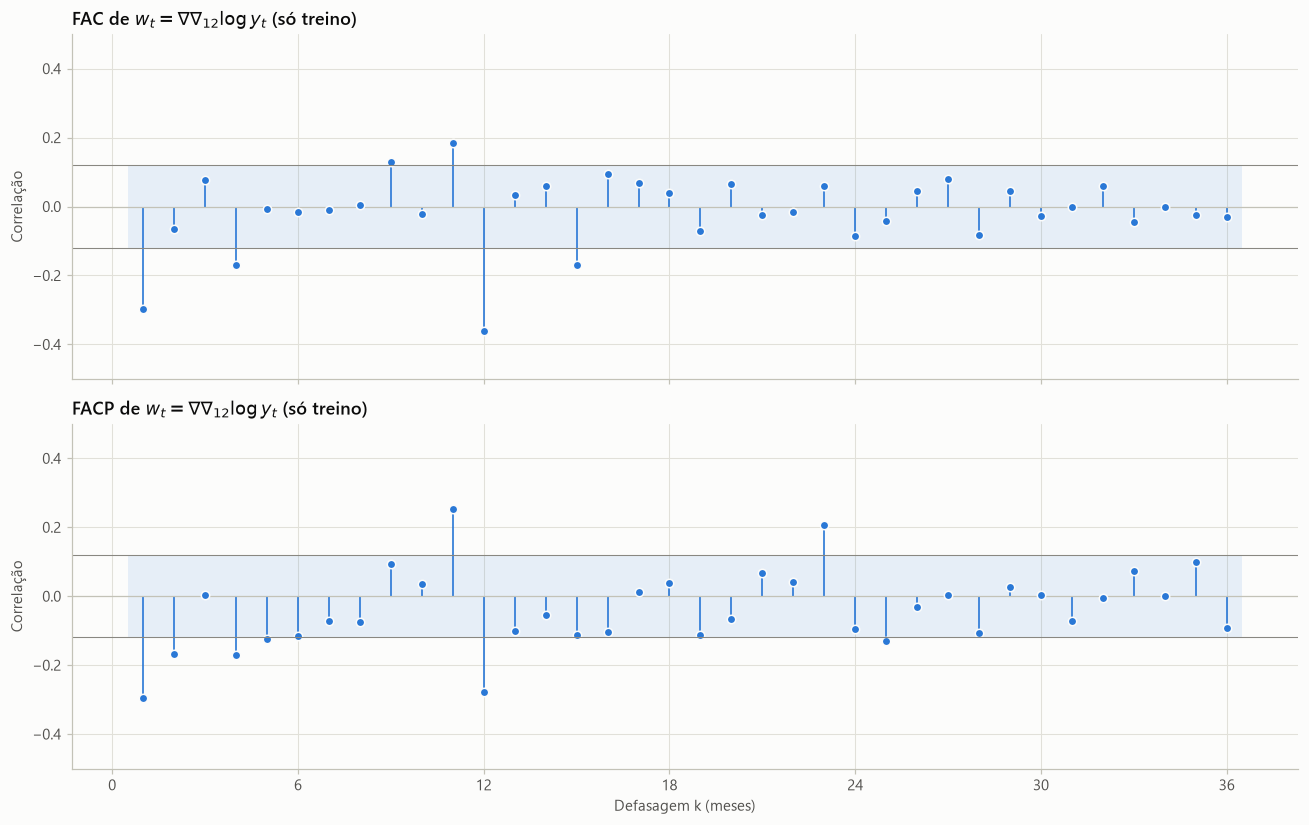

FAC fora da banda:  {1: -0.297, 4: -0.168, 9: 0.129, 11: 0.184, 12: -0.361, 15: -0.171}
FACP fora da banda: {1: -0.297, 2: -0.169, 4: -0.171, 5: -0.123, 11: 0.254, 12: -0.277, 23: 0.207, 25: -0.131}
lags 1 a 6 | FAC:  [-0.297 -0.066  0.077 -0.168 -0.008 -0.017]
lags 1 a 6 | FACP: [-0.297 -0.169  0.004 -0.171 -0.123 -0.116]


In [4]:
w_treino = treino.diff(12).diff().dropna()
banda = 1.96 / np.sqrt(len(w_treino))
print(f"w_t no treino: n = {len(w_treino)} | média = {w_treino.mean():.5f} | banda = ±1.96/√n = ±{banda:.3f}")

estilo = dict(zero=False, color=AZUL, markersize=5.5, markeredgecolor=FUNDO, markeredgewidth=1.0,
              vlines_kwargs={"colors": AZUL, "linewidth": 1.1})
fig, axs = plt.subplots(2, 1, figsize=(12, 7.6), sharex=True)
plot_acf(w_treino, ax=axs[0], lags=36, bartlett_confint=False,
         title=r"FAC de $w_t = \nabla\nabla_{12}\log y_t$ (só treino)", **estilo)
plot_pacf(w_treino, ax=axs[1], lags=36, method="ywm",
          title=r"FACP de $w_t = \nabla\nabla_{12}\log y_t$ (só treino)", **estilo)
for ax in axs:
    estilizar_correlograma(ax, banda)
    ax.set_xticks(range(0, 37, 6))
    ax.set_ylim(-0.5, 0.5)
    ax.set_ylabel("Correlação")
axs[1].set_xlabel("Defasagem k (meses)")
plt.tight_layout()
plt.show()

fac = acf(w_treino, nlags=36)
facp = pacf(w_treino, nlags=36, method="ywm")
print("FAC fora da banda: ", {k: round(float(fac[k]), 3) for k in range(1, 37) if abs(fac[k]) > banda})
print("FACP fora da banda:", {k: round(float(facp[k]), 3) for k in range(1, 37) if abs(facp[k]) > banda})
print("lags 1 a 6 | FAC: ", np.round(fac[1:7], 3))
print("lags 1 a 6 | FACP:", np.round(facp[1:7], 3))

Para escolher p e q, o que interessa é a parte não sazonal, ou seja, os primeiros lags:

- **FAC:** tem um pico grande no lag 1 (−0,30) e depois fica praticamente dentro da banda: os lags 2, 3, 5 e 6 estão perto de zero, e só o lag 4 (−0,17) escapa. Dá para dizer que a FAC "corta" depois do lag 1.
- **FACP:** os lags 1 (−0,30) e 2 (−0,17) estão fora da banda, o lag 3 é praticamente zero (0,004) e os lags 4 e 5 voltam a sair (−0,17 e −0,12). Os valores negativos vão diminuindo aos poucos, o que parece mais um decaimento do que um corte.

Os lags 11, 12 e 13 da FAC (e 11, 12, 23 e 25 da FACP) são a parte sazonal. Um ARIMA(p, d, q) com p e q até 4 não alcança o lag 12, então por enquanto só deixo isso anotado e volto a esse ponto no final.

### 1.3 Tabela de candidatos

Os gráficos não cortam de um jeito limpo como nos exemplos dos livros, então propus quatro candidatos, cada um seguindo uma leitura possível:

| Candidato | Padrão do correlograma que motivou a escolha |
|---|---|
| ARIMA(0,1,1) | A FAC corta depois do lag 1 e a FACP decai aos poucos. É o padrão clássico de um MA(1), e foi a minha primeira aposta. |
| ARIMA(2,1,0) | Lendo pela FACP: os lags 1 e 2 são significativos e o lag 3 é praticamente zero, então a FACP cortaria no lag 2, o que sugere um AR(2). |
| ARIMA(1,1,1) | Como nenhuma das duas funções corta de forma totalmente limpa, um modelo misto pequeno é uma alternativa parcimoniosa que pode capturar os dois comportamentos ao mesmo tempo. |
| ARIMA(4,1,0) | Se eu levar a sério o lag 4, que aparece fora da banda nas duas funções, a FACP só "acaba" depois do lag 4 ou 5. O AR(4) é o maior que cabe na grade e serve para testar se esse lag importa. |

## Item 2 — Estimação: ajuste e busca em grade

### 2.1 Ajuste dos candidatos

Todos os modelos são ajustados por máxima verossimilhança com o `statsmodels.tsa.arima.model.ARIMA`, que escreve o modelo em espaço de estados e calcula a verossimilhança exata com o filtro de Kalman. O ajuste usa só os 283 meses de treino. Dois detalhes de implementação:

- aumentei o número máximo de iterações do otimizador para 1000, porque com o padrão (50) vários modelos maiores terminavam sem convergir;
- o `statsmodels` conta a variância do erro ($\sigma^2$) como parâmetro, então nas tabelas $k = p + q + 1$. Como esse +1 aparece em todos os modelos, ele não muda a comparação.

Outro cuidado importante é que o AIC e o BIC só podem ser comparados entre modelos ajustados nos mesmos dados. Por isso todos os modelos daqui têm exatamente as mesmas diferenças ($d = 1$ e $D = 1$) e o mesmo treino.

In [5]:
def ajustar(p, q, sazonal=(0, 1, 0, 12)):
    """ARIMA(p,1,q) no log do treino, com a diferença sazonal fixa (o (0,1,0,12) só aplica ∇12)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # a convergência é conferida depois, em mle_retvals
        modelo = ARIMA(treino, order=(p, 1, q), seasonal_order=sazonal)
        return modelo.fit(method_kwargs={"maxiter": 1000})


def coeficientes(modelo):
    """Texto curto com cada coeficiente e o seu p-valor (sem o sigma2)."""
    partes = []
    for nome in modelo.params.index:
        if nome != "sigma2":
            partes.append(f"{nome} = {modelo.params[nome]:+.3f} (p = {modelo.pvalues[nome]:.3f})")
    return "; ".join(partes)


candidatos = [(0, 1), (2, 0), (1, 1), (4, 0)]
ajustados = {}
linhas = []
for p, q in candidatos:
    m = ajustar(p, q)
    ajustados[(p, q)] = m
    print(f"ARIMA({p},1,{q}): {coeficientes(m)}")
    linhas.append({"modelo": f"ARIMA({p},1,{q})", "k": len(m.params), "log-verossimilhança": m.llf,
                   "AIC": m.aic, "BIC": m.bic, "convergiu": bool(m.mle_retvals["converged"])})
pd.DataFrame(linhas).set_index("modelo").round(2)

ARIMA(0,1,1): ma.L1 = -0.408 (p = 0.000)


ARIMA(2,1,0): ar.L1 = -0.348 (p = 0.000); ar.L2 = -0.169 (p = 0.000)


ARIMA(1,1,1): ar.L1 = +0.448 (p = 0.000); ma.L1 = -0.812 (p = 0.000)


ARIMA(4,1,0): ar.L1 = -0.347 (p = 0.000); ar.L2 = -0.197 (p = 0.000); ar.L3 = -0.053 (p = 0.304); ar.L4 = -0.175 (p = 0.001)


,k,log-verossimilhança,AIC,BIC,convergiu
modelo,,,,,
"ARIMA(0,1,1)",2,532.44,-1060.88,-1053.68,True
"ARIMA(2,1,0)",3,532.07,-1058.14,-1047.34,True
"ARIMA(1,1,1)",3,536.15,-1066.31,-1055.51,True
"ARIMA(4,1,0)",5,536.21,-1062.42,-1044.42,True


Os quatro candidatos convergiram. Entre eles, o melhor é o ARIMA(1,1,1), tanto pelo AIC (−1066,3) quanto pelo BIC (−1055,5). No (1,1,1), no (0,1,1) e no (2,1,0), todos os coeficientes são significativos. No (4,1,0), o `ar.L3` não é significativo (p = 0,30), mas o `ar.L4` é (p < 0,001). Ou seja, o lag 4 que apareceu nos correlogramas parece importar de verdade, e não só como ruído.

### 2.2 Busca em grade

Para não depender só da minha leitura dos gráficos, testei todas as combinações com $p \in \{0, \dots, 4\}$ e $q \in \{0, \dots, 4\}$, com $d = 1$ fixo, o que dá 25 modelos.

In [6]:
resultados = []
for p, q in itertools.product(range(5), range(5)):
    m = ajustar(p, q)
    resultados.append({"ordem": f"({p},1,{q})", "p": p, "q": q, "k": len(m.params),
                       "AIC": m.aic, "BIC": m.bic, "convergiu": bool(m.mle_retvals["converged"])})
grade = pd.DataFrame(resultados)

sem_convergir = grade.loc[~grade["convergiu"], "ordem"].tolist()
print(f"{len(grade)} modelos ajustados | sem convergência mesmo com 1000 iterações: {sem_convergir}")

25 modelos ajustados | sem convergência mesmo com 1000 iterações: ['(0,1,0)', '(3,1,2)']


### 2.3 Tabela consolidada

A tabela está ordenada pelo AIC. Os candidatos do Item 1 aparecem em negrito e marcados na última coluna, e também incluí a posição de cada modelo no ranking do BIC.

In [7]:
tabela = grade.sort_values("AIC").reset_index(drop=True)
tabela.insert(0, "posição AIC", range(1, len(tabela) + 1))
tabela["ΔAIC"] = tabela["AIC"] - tabela["AIC"].min()
tabela["posição BIC"] = tabela["BIC"].rank().astype(int)
tabela["candidato do Item 1"] = ["sim" if (p, q) in candidatos else "" for p, q in zip(tabela["p"], tabela["q"])]
colunas = ["posição AIC", "ordem", "k", "AIC", "ΔAIC", "BIC", "posição BIC", "convergiu", "candidato do Item 1"]


def negrito_candidatos(linha):
    return ["font-weight: bold" if linha["candidato do Item 1"] == "sim" else "" for _ in linha]


(tabela[colunas].style
 .format({"AIC": "{:.2f}", "ΔAIC": "{:.2f}", "BIC": "{:.2f}"})
 .apply(negrito_candidatos, axis=1)
 .hide(axis="index"))

posição AIC,ordem,k,AIC,ΔAIC,BIC,posição BIC,convergiu,candidato do Item 1
1,"(3,1,4)",8,-1083.20,0.00,-1054.41,2,True,
2,"(2,1,4)",7,-1074.16,9.04,-1048.97,10,True,
3,"(2,1,3)",6,-1073.27,9.93,-1051.68,7,True,
4,"(1,1,4)",6,-1072.90,10.30,-1051.31,8,True,
5,"(3,1,2)",6,-1072.61,10.59,-1051.02,9,False,
6,"(4,1,3)",8,-1071.15,12.05,-1042.36,19,True,
7,"(4,1,4)",9,-1070.93,12.27,-1038.55,24,True,
8,"(0,1,4)",5,-1070.76,12.43,-1052.77,4,True,
9,"(2,1,2)",5,-1069.99,13.21,-1052.00,6,True,
10,"(4,1,1)",6,-1068.50,14.70,-1046.91,15,True,


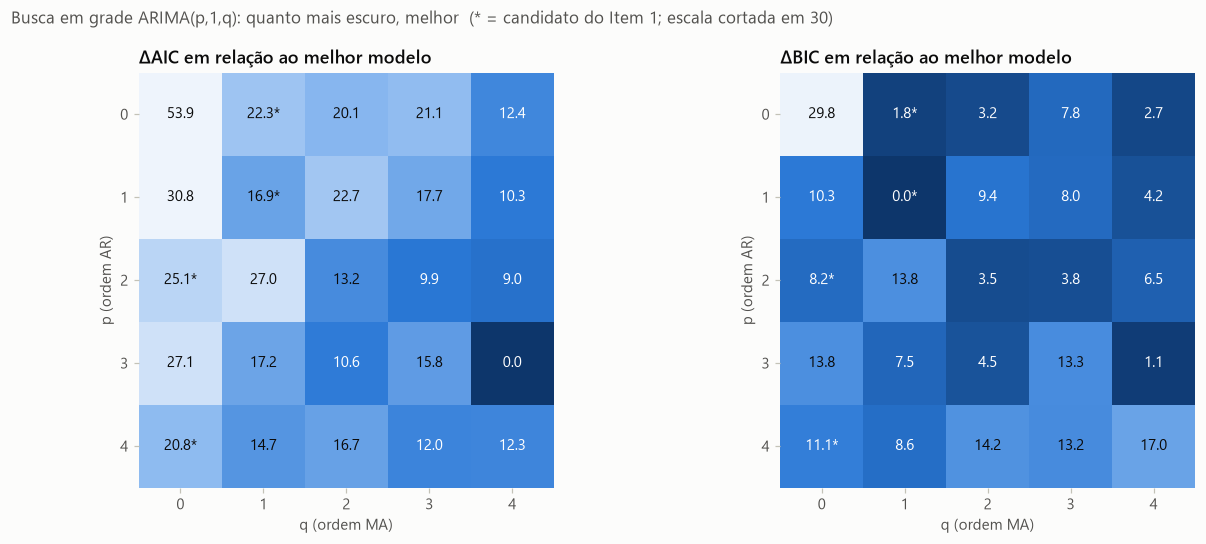

In [8]:
# mapa de calor da grade: diferença para o melhor modelo em cada critério (0 = campeão)
azuis = LinearSegmentedColormap.from_list("azuis", ["#0d366b", "#2a78d6", "#86b6ef", "#eef4fc"])

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, criterio in zip(axs, ["AIC", "BIC"]):
    matriz = grade.pivot(index="p", columns="q", values=criterio)
    delta = matriz - matriz.min().min()
    ax.imshow(delta.clip(upper=30), cmap=azuis, vmin=0, vmax=30)
    for p in range(5):
        for q in range(5):
            valor = delta.loc[p, q]
            marca = "*" if (p, q) in candidatos else ""
            ax.text(q, p, f"{valor:.1f}{marca}", ha="center", va="center", fontsize=9.5,
                    color="white" if valor < 13 else TINTA)
    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    ax.set_xlabel("q (ordem MA)")
    ax.set_ylabel("p (ordem AR)")
    ax.set_title(f"Δ{criterio} em relação ao melhor modelo")
    ax.grid(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_visible(False)
fig.suptitle("Busca em grade ARIMA(p,1,q): quanto mais escuro, melhor  (* = candidato do Item 1; escala cortada em 30)",
             x=0.01, ha="left", fontsize=11, color=TINTA_2)
plt.tight_layout()
plt.show()

Algumas coisas chamam atenção:

- Pelo AIC, o primeiro lugar é o **ARIMA(3,1,4)**, com 8 parâmetros, que não estava entre os meus candidatos. Os meus candidatos ficaram em 13º (1,1,1), 17º (4,1,0), 19º (0,1,1) e 21º (2,1,0) lugar.
- Pelo BIC, o primeiro lugar é o **ARIMA(1,1,1)**, que era um dos meus candidatos, e o (0,1,1) aparece em 3º. Os cinco melhores pelo BIC estão a menos de 3,2 pontos do primeiro.
- Mesmo com 1000 iterações, dois modelos não convergiram: o (0,1,0), que é o modelo trivial e só tem a variância, e o (3,1,2). Os números deles devem ser lidos com cuidado, mas nenhum dos dois entra na disputa pelo primeiro lugar.

Os mapas de calor mostram bem a diferença entre os dois critérios. No AIC, as células escuras ficam no canto de p e q grandes. No BIC, elas se concentram perto da origem (p e q pequenos), com o (3,1,4) aparecendo quase empatado.

## Item 3 — Seleção do modelo via critérios de informação

### 3.1 AIC ou BIC?

Antes de escolher, comparei de perto os dois campeões.

In [9]:
melhor_aic = grade.loc[grade["AIC"].idxmin()]
melhor_bic = grade.loc[grade["BIC"].idxmin()]
m_aic = ajustar(int(melhor_aic["p"]), int(melhor_aic["q"]))
m_bic = ajustar(int(melhor_bic["p"]), int(melhor_bic["q"]))

for rotulo, linha, m in [("menor AIC", melhor_aic, m_aic), ("menor BIC", melhor_bic, m_bic)]:
    print(f"ARIMA{linha['ordem']} ({rotulo}): AIC = {m.aic:.2f} | BIC = {m.bic:.2f} | k = {len(m.params)}")
    print("   ", coeficientes(m))
    print("    raízes AR:", np.round(m.arroots, 3), "-> módulos", np.round(np.abs(m.arroots), 3))
    print("    raízes MA:", np.round(m.maroots, 3), "-> módulos", np.round(np.abs(m.maroots), 3))
    print()
print(f"diferença de AIC entre os dois: {m_bic.aic - m_aic.aic:.2f} | diferença de BIC: {m_aic.bic - m_bic.bic:.2f}")
print(f"penalidade por parâmetro: AIC = 2 | BIC = ln(n) = ln({m_aic.nobs_effective}) = {np.log(m_aic.nobs_effective):.2f}")

ARIMA(3,1,4) (menor AIC): AIC = -1083.20 | BIC = -1054.41 | k = 8
    ar.L1 = +0.438 (p = 0.000); ar.L2 = +0.148 (p = 0.096); ar.L3 = -0.687 (p = 0.000); ma.L1 = -0.844 (p = 0.000); ma.L2 = -0.080 (p = 0.304); ma.L3 = +0.953 (p = 0.000); ma.L4 = -0.560 (p = 0.000)
    raízes AR: [ 0.729-0.801j  0.729+0.801j -1.242-0.j   ] -> módulos [1.083 1.083 1.242]
    raízes MA: [-1.053-0.j     0.643-0.861j  0.643+0.861j  1.469-0.j   ] -> módulos [1.053 1.075 1.075 1.469]

ARIMA(1,1,1) (menor BIC): AIC = -1066.31 | BIC = -1055.51 | k = 3
    ar.L1 = +0.448 (p = 0.000); ma.L1 = -0.812 (p = 0.000)
    raízes AR: [2.23] -> módulos [2.23]
    raízes MA: [1.232] -> módulos [1.232]

diferença de AIC entre os dois: 16.89 | diferença de BIC: 1.10
penalidade por parâmetro: AIC = 2 | BIC = ln(n) = ln(270) = 5.60


Os dois critérios usam a mesma log-verossimilhança e só mudam na penalidade por parâmetro: o AIC cobra 2 pontos por parâmetro, e o BIC cobra $\ln(n)$, que aqui é $\ln(270) \approx 5{,}6$. Como o (3,1,4) tem 8 parâmetros contra 3 do (1,1,1), ele paga uma penalidade bem maior no BIC, e é por isso que os dois discordam. Pelo AIC, a vantagem do (3,1,4) é de 16,9 pontos; pelo BIC, a vantagem do (1,1,1) é de apenas 1,1.

Tive que decidir qual seguir e fiquei com o **BIC**, então o meu campeão é o **ARIMA(1,1,1)**. Os motivos:

1. O (3,1,4) tem cara de modelo com parâmetros sobrando. Dois coeficientes não são significativos (`ar.L2`, com p = 0,10, e `ma.L2`, com p = 0,30), as menores raízes estão perto do círculo unitário (módulos entre 1,05 e 1,08) e o par de raízes complexas do AR (0,73 ± 0,80i) é parecido com um par do MA (0,64 ± 0,86i). Quando isso acontece, parte dos termos AR e MA se cancela, e o modelo fica maior do que precisaria.
2. Essa região da grade foi justamente a que deu problema de convergência. Com as 50 iterações padrão do `statsmodels`, o próprio (3,1,4) não convergia, e o (3,1,2), vizinho dele, não converge nem com 1000.
3. O AIC tem a fama de escolher modelos maiores do que o necessário, porque a penalidade dele é leve. Já o BIC é consistente: com dados suficientes, ele tende a escolher a ordem verdadeira.
4. O (1,1,1) tem os dois coeficientes muito significativos, raízes longe do círculo unitário (2,23 no AR e 1,23 no MA) e era um dos meus candidatos.

Mas não dá para simplesmente ignorar o AIC. Uma diferença de 16,9 pontos é grande: pela regra de Burnham e Anderson, acima de 10 o modelo pior tem pouquíssimo suporte. Minha interpretação é que o AIC está percebendo uma estrutura real que os modelos pequenos não capturam, e o (3,1,4) tenta absorver essa estrutura com polinômios de ordem alta. Na seção "Indo além" eu mostro que o que faltava era, principalmente, a sazonalidade.

### 3.2 Princípio da parcimônia

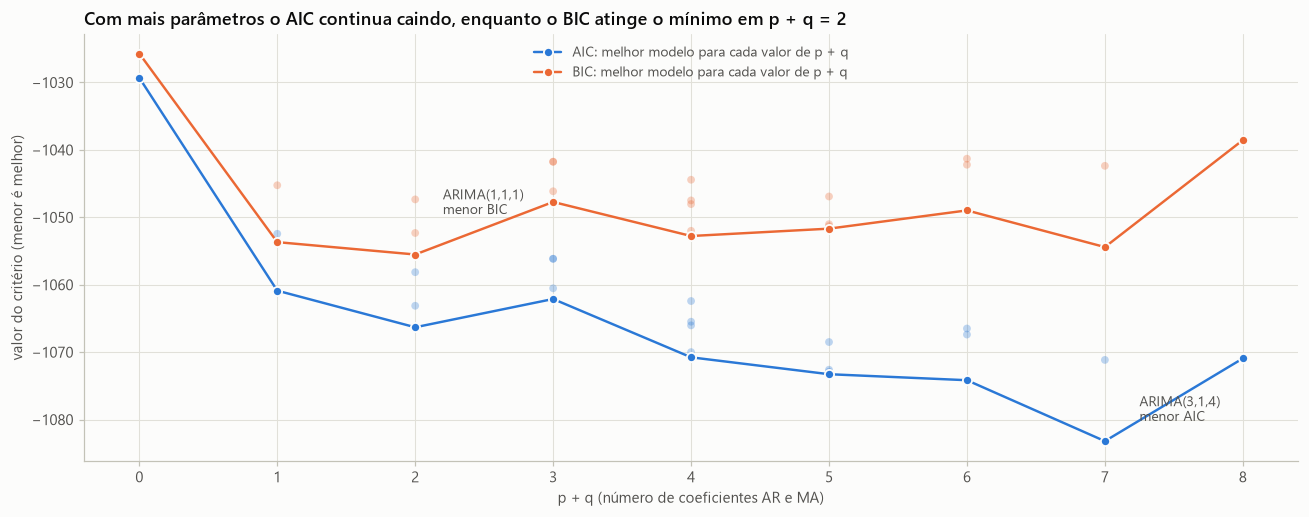

In [10]:
grade["p+q"] = grade["p"] + grade["q"]

fig, ax = plt.subplots(figsize=(12, 4.8))
for criterio, cor in [("AIC", AZUL), ("BIC", LARANJA)]:
    ax.scatter(grade["p+q"], grade[criterio], s=26, color=cor, alpha=0.3, edgecolors="none")
    melhores = grade.groupby("p+q")[criterio].min()
    ax.plot(melhores.index, melhores.values, color=cor, marker="o", markersize=6, markeredgecolor=FUNDO,
            markeredgewidth=1.2, label=f"{criterio}: melhor modelo para cada valor de p + q")
ax.annotate("ARIMA(3,1,4)\nmenor AIC", xy=(7, m_aic.aic), xytext=(7.25, m_aic.aic + 3), fontsize=9, color=TINTA_2)
ax.annotate("ARIMA(1,1,1)\nmenor BIC", xy=(2, m_bic.bic), xytext=(2.2, m_bic.bic + 6), fontsize=9, color=TINTA_2)
ax.set_xticks(range(9))
ax.set_xlabel("p + q (número de coeficientes AR e MA)")
ax.set_ylabel("valor do critério (menor é melhor)")
ax.set_title("Com mais parâmetros o AIC continua caindo, enquanto o BIC atinge o mínimo em p + q = 2")
ax.legend(loc="upper center")
plt.tight_layout()
plt.show()

O modelo de menor AIC não é o mais parcimonioso: ele tem p + q = 7. O gráfico mostra o comportamento dos dois critérios conforme o modelo cresce. O AIC cai quase sempre, porque cada parâmetro novo melhora um pouco o ajuste e custa só 2 pontos (basta a log-verossimilhança subir mais de 1). O BIC atinge o mínimo em p + q = 2 e depois fica parado ou piora, com exceção do próprio (3,1,4), que quase empata.

Pensando em parcimônia, ainda daria para ir um passo além. O ARIMA(0,1,1) fica só 1,8 ponto de BIC atrás do (1,1,1), com um coeficiente a menos. Mas aí o AIC prefere o (1,1,1) por 5,4 pontos, e o coeficiente AR é altamente significativo (p < 0,001), então os dois critérios concordam que esse termo vale a pena. Por isso acho que o (1,1,1) é o melhor equilíbrio: ele é o primeiro pelo BIC e, entre os modelos com p + q ≤ 2, também é o primeiro pelo AIC. Na prática, eu preferiria ele a um modelo com 7 coeficientes que ganha no AIC, mas tem termos redundantes.

### 3.3 Resumo estatístico do modelo campeão

In [11]:
campeao = m_bic
print(campeao.summary())
print(f"\ndesvio-padrão do erro: σ = √{campeao.params['sigma2']:.5f} = {np.sqrt(campeao.params['sigma2']):.4f}")
maiores = campeao.resid.iloc[13:].abs().nlargest(3).index
print("maiores resíduos (em módulo):", ", ".join(f"{d:%m/%Y} ({campeao.resid[d]:+.3f})" for d in maiores))

                                     SARIMAX Results                                     
Dep. Variable:                     indice_volume   No. Observations:                  283
Model:             ARIMA(1, 1, 1)x(0, 1, [], 12)   Log Likelihood                 536.155
Date:                           Wed, 14 Oct 2026   AIC                          -1066.310
Time:                                   20:03:45   BIC                          -1055.514
Sample:                               01-01-2000   HQIC                         -1061.975
                                    - 07-01-2023                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4485      0.092      4.896      0.000       0.269       0.628
ma.L1         -0.8118      0.063    -12.912

O modelo ajustado para $w_t = \nabla\nabla_{12}\log y_t$ é

$$w_t = 0{,}449\, w_{t-1} + \varepsilon_t - 0{,}812\, \varepsilon_{t-1}, \qquad \hat\sigma = 0{,}033.$$

Lendo o `.summary()`:

- **Coeficientes.** $\hat\phi_1 = 0{,}449$ (z = 4,9) e $\hat\theta_1 = -0{,}812$ (z = −12,9) têm p-valor < 0,001, então os dois são estatisticamente diferentes de zero e nenhum termo está sobrando. Os intervalos de 95% (de 0,27 a 0,63 e de −0,94 a −0,69) ficam longe de zero e também longe de 1 em módulo. O sinal negativo do MA combina com o que a FAC mostrou no lag 1 (−0,30): um mês acima do esperado tende a ser parcialmente compensado no mês seguinte.
- **Estacionariedade e invertibilidade.** A raiz do polinômio AR é 2,23 e a do MA é 1,23, as duas fora do círculo unitário, então o modelo é estacionário e invertível.
- **Variância do erro.** $\hat\sigma^2 = 0{,}0011$, ou seja, um erro típico de cerca de 3,3% ao mês na escala do log.
- **Diagnósticos do rodapé.** O Ljung-Box no lag 1 (p = 0,61) não acusa nada. O Jarque-Bera (p < 0,001, curtose de 10,5) rejeita a normalidade dos resíduos. Os dois maiores resíduos são abril de 2021 (+0,195) e abril de 2020 (−0,190), ou seja, o choque da COVID e o efeito de base um ano depois. O teste de heterocedasticidade (H = 2,21, p < 0,001) indica que a variância dos resíduos no último terço do treino é cerca de 2,2 vezes a do primeiro terço. Isso não invalida a escolha feita pelos critérios de informação, mas é o tipo de coisa que a fase de verificação vai precisar olhar com calma.



O enunciado diz que a verificação vai ser aprofundada em um trabalho futuro, então aqui faço só uma checagem rápida, para fechar o ciclo uma vez. Se o modelo estiver bom, os resíduos devem se comportar como ruído branco, sem autocorrelação. Para isso olhei a FAC dos resíduos e o teste de Ljung-Box, cuja hipótese nula é de que não há autocorrelação até o lag testado. Os 13 primeiros resíduos ficam de fora, porque correspondem à inicialização das diferenças (1 + 12).

In [12]:
residuos = campeao.resid.iloc[13:]
lb_campeao = acorr_ljungbox(residuos, lags=[12, 24], model_df=2)  # model_df = p + q
print("Ljung-Box nos resíduos do ARIMA(1,1,1):")
print(lb_campeao.round(4))

Ljung-Box nos resíduos do ARIMA(1,1,1):
    lb_stat  lb_pvalue
12  51.0114        0.0
24  67.8195        0.0


O resultado é claro: com Q(12) = 51,0 e p < 0,0001, o teste rejeita a hipótese de resíduos sem autocorrelação, tanto até o lag 12 quanto até o lag 24. Pelo ciclo de Box-Jenkins, esse é o ponto em que é preciso voltar para a identificação.

E não precisei procurar muito, porque o problema já era conhecido. No Item 1 eu deixei anotado que a FAC de $w_t$ tinha −0,36 no lag 12 e que um ARIMA com p e q até 4 não alcança esse lag. Esse pico sazonal tem o mesmo formato do pico do lag 1: um valor isolado seguido de um corte, já que nos lags 24 e 36 a FAC fica dentro da banda. Pela mesma regra que usei para escolher o q, isso pede um **MA sazonal de ordem 1** ($Q = 1$). O modelo vira um SARIMA$(p,1,q)(0,1,1)_{12}$, que nada mais é do que o ARIMA do enunciado com um termo a mais no lag 12:

$$\phi(L)\,(1-L)(1-L^{12})\log y_t = \theta(L)\,(1 + \Theta_1 L^{12})\,\varepsilon_t.$$

Testei o termo sazonal junto com o meu campeão (1,1,1) e com os dois candidatos mais simples, (0,1,1) e (2,1,0). A versão com o (0,1,1) é exatamente o "modelo das companhias aéreas" de Box e Jenkins, que eu tinha mencionado no Trabalho I.

In [13]:
modelos_sazonais = {
    "SARIMA(0,1,1)(0,1,1)12": (0, 1),
    "SARIMA(1,1,1)(0,1,1)12": (1, 1),
    "SARIMA(2,1,0)(0,1,1)12": (2, 0),
}
linhas = [{"modelo": "ARIMA(1,1,1), campeão do Item 3", "k": len(campeao.params), "AIC": campeao.aic,
           "BIC": campeao.bic, "Ljung-Box Q(12)": lb_campeao.loc[12, "lb_stat"],
           "Ljung-Box p (lag 12)": lb_campeao.loc[12, "lb_pvalue"], "convergiu": bool(campeao.mle_retvals["converged"])}]
sazonais = {}
for nome, (p, q) in modelos_sazonais.items():
    m = ajustar(p, q, sazonal=(0, 1, 1, 12))
    sazonais[nome] = m
    lb = acorr_ljungbox(m.resid.iloc[13:], lags=[12], model_df=p + q + 1)
    linhas.append({"modelo": nome, "k": len(m.params), "AIC": m.aic, "BIC": m.bic,
                   "Ljung-Box Q(12)": lb["lb_stat"].iloc[0], "Ljung-Box p (lag 12)": lb["lb_pvalue"].iloc[0],
                   "convergiu": bool(m.mle_retvals["converged"])})
pd.DataFrame(linhas).set_index("modelo").round(4)

,k,AIC,BIC,Ljung-Box Q(12),Ljung-Box p (lag 12),convergiu
modelo,,,,,,
"ARIMA(1,1,1), campeão do Item 3",3,-1066.3097,-1055.5144,51.0114,0.0000,True
"SARIMA(0,1,1)(0,1,1)12",3,-1134.5849,-1123.7896,28.9476,0.0013,True
"SARIMA(1,1,1)(0,1,1)12",4,-1136.1917,-1121.7980,24.6988,0.0033,True
"SARIMA(2,1,0)(0,1,1)12",4,-1132.7502,-1118.3565,28.6528,0.0007,True


A melhora é enorme. Com o mesmo número de parâmetros do campeão do Item 3 (k = 3), o SARIMA(0,1,1)(0,1,1)₁₂ tem AIC de −1134,6 contra −1066,3, uma melhora de 68 pontos. Ele também supera o (3,1,4), o melhor da grade pelo AIC, por 51 pontos, usando 2 coeficientes em vez de 7. Ou seja, um único termo no lugar certo vale mais do que vários termos não sazonais.

Entre os modelos sazonais, o AIC e o BIC voltam a discordar, mas agora por pouco. O (1,1,1)(0,1,1)₁₂ tem o menor AIC (−1136,2), só 1,6 ponto à frente do (0,1,1)(0,1,1)₁₂, e o (0,1,1)(0,1,1)₁₂ tem o menor BIC (−1123,8), 2 pontos à frente. Com uma diferença de AIC menor que 2, os dois são praticamente equivalentes, e aí a parcimônia desempata: fico com o **SARIMA(0,1,1)(0,1,1)₁₂**, que tem um parâmetro a menos. É o modelo que eu tinha imaginado no Trabalho I só de olhar a FAC.

In [14]:
airline = sazonais["SARIMA(0,1,1)(0,1,1)12"]
print(airline.summary())

                                    SARIMAX Results                                     
Dep. Variable:                    indice_volume   No. Observations:                  283
Model:             ARIMA(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 570.292
Date:                          Wed, 14 Oct 2026   AIC                          -1134.585
Time:                                  20:03:51   BIC                          -1123.790
Sample:                              01-01-2000   HQIC                         -1130.250
                                   - 07-01-2023                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4038      0.045     -8.875      0.000      -0.493      -0.315
ma.S.L12      -0.6576      0.039    -16.955      0.

ARIMA(1,1,1): lags fora da banda nos resíduos -> {4: -0.119, 9: 0.124, 12: -0.355, 15: -0.174}
SARIMA(0,1,1)(0,1,1)12: lags fora da banda nos resíduos -> {4: -0.18, 9: 0.203, 13: -0.139, 15: -0.135, 20: 0.129, 32: 0.128}


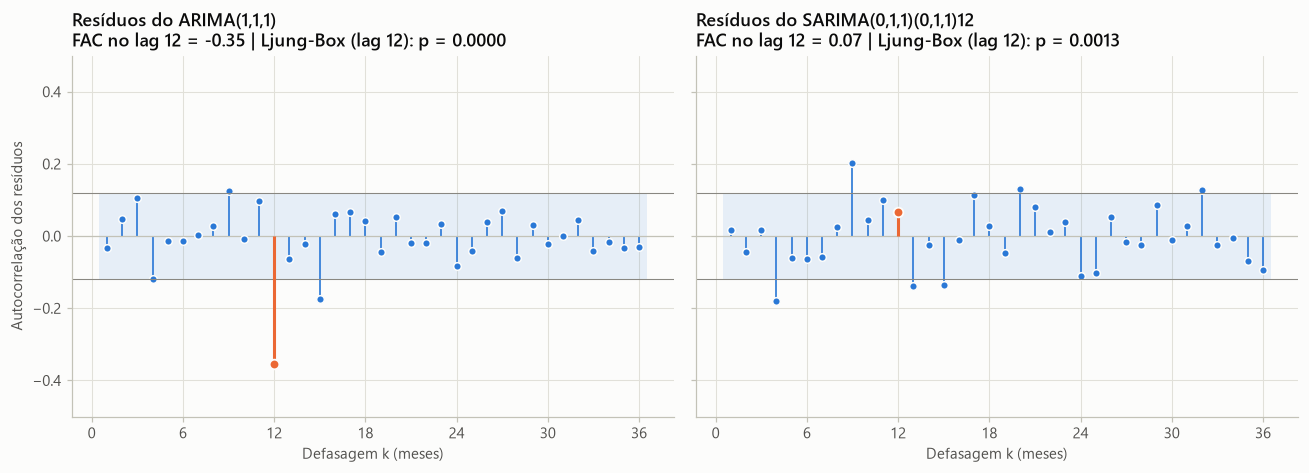

In [15]:
# FAC dos resíduos antes e depois do MA sazonal (lag 12 em laranja); os dois modelos têm p + q = 2
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, (titulo, m) in zip(axs, [("ARIMA(1,1,1)", campeao), ("SARIMA(0,1,1)(0,1,1)12", airline)]):
    r = m.resid.iloc[13:]
    banda_r = 1.96 / np.sqrt(len(r))
    fac_r = acf(r, nlags=36)
    p_lb = acorr_ljungbox(r, lags=[12], model_df=2)["lb_pvalue"].iloc[0]
    plot_acf(r, ax=ax, lags=36, zero=False, bartlett_confint=False,
             title=f"Resíduos do {titulo}\nFAC no lag 12 = {fac_r[12]:.2f} | Ljung-Box (lag 12): p = {p_lb:.4f}",
             color=AZUL, markersize=5, markeredgecolor=FUNDO, markeredgewidth=1.0,
             vlines_kwargs={"colors": AZUL, "linewidth": 1.1})
    estilizar_correlograma(ax, banda_r)
    ax.vlines([12], 0, [fac_r[12]], colors=LARANJA, linewidth=2)
    ax.scatter([12], [fac_r[12]], s=40, color=LARANJA, edgecolors=FUNDO, linewidths=1.2, zorder=4)
    ax.set_xticks(range(0, 37, 6))
    ax.set_ylim(-0.5, 0.5)
    ax.set_xlabel("Defasagem k (meses)")
    print(f"{titulo}: lags fora da banda nos resíduos ->",
          {k: round(float(fac_r[k]), 3) for k in range(1, 37) if abs(fac_r[k]) > banda_r})
axs[0].set_ylabel("Autocorrelação dos resíduos")
plt.tight_layout()
plt.show()

No `.summary()` do SARIMA(0,1,1)(0,1,1)₁₂, os dois coeficientes são muito significativos: $\hat\theta_1 = -0{,}404$ (z = −8,9) e $\hat\Theta_1 = -0{,}658$ (z = −17,0), os dois com p < 0,001. Um $\hat\Theta_1$ negativo e grande significa que o padrão sazonal de cada mês é atualizado aos poucos de um ano para o outro, em vez de ficar fixo. Isso combina com o que eu vi no Trabalho I, quando o peso de dezembro foi caindo e o de novembro subindo depois da chegada da Black Friday. A variância do erro também caiu, de 0,0011 para 0,0008.

O gráfico compara os resíduos dos dois modelos. O pico de −0,35 no lag 12 do ARIMA(1,1,1) praticamente desapareceu (0,07 no SARIMA), e o Q(12) do Ljung-Box caiu de 51,0 para 28,9. Mesmo assim, o teste ainda rejeita o ruído branco (p = 0,0013). O que sobrou está em lags isolados, principalmente o 4 (−0,18) e o 9 (+0,20). O lag 4 já tinha aparecido na identificação e é provavelmente parte do que o (3,1,4) estava tentando capturar. Tenho algumas hipóteses para essas sobras, como efeitos de calendário (o Carnaval e a Páscoa mudam de mês de um ano para o outro) e os valores extremos da pandemia, mas investigar isso é trabalho da fase de verificação, que vai ser aprofundada no próximo trabalho.

## Considerações finais

### Síntese do processo de identificação e estimação

Na identificação, o ADF do Trabalho I (refeito aqui, inclusive só com o treino) definiu $d = 1$, com a diferença sazonal mantida como passo fixo. Relendo a FAC e a FACP de $w_t$, propus quatro candidatos: ARIMA(0,1,1), (2,1,0), (1,1,1) e (4,1,0). Na estimação, ajustei esses candidatos e uma grade com 25 combinações de p e q (de 0 a 4) por máxima verossimilhança, só nos 283 meses de treino. Os últimos 36 meses ficaram guardados e não foram usados em nenhuma etapa deste trabalho.

O AIC escolheu o ARIMA(3,1,4) e o BIC escolheu o ARIMA(1,1,1). Fiquei com o **ARIMA(1,1,1)** como campeão do Item 3, pelo BIC, pela parcimônia, pelos coeficientes significativos e pelos sinais de redundância e instabilidade do (3,1,4). Depois, uma checagem rápida dos resíduos mostrou autocorrelação no lag 12. Voltando à identificação, acrescentei um MA sazonal e cheguei ao **SARIMA(0,1,1)(0,1,1)₁₂**, que melhora o AIC em 68 pontos com o mesmo número de parâmetros. É esse o modelo que eu levaria para a próxima etapa.

### Reflexão crítica

Os candidatos que propus olhando os correlogramas coincidiram com o vencedor do BIC, mas não com o do AIC. O (1,1,1) era um dos meus quatro candidatos e ficou em primeiro pelo BIC, e o (0,1,1), que foi a minha primeira aposta, ficou em terceiro. Já pelo AIC os meus candidatos ficaram entre o 13º e o 21º lugar, e o vencedor foi um modelo com 7 coeficientes que eu não teria proposto olhando os gráficos.

Acho que isso acontece porque a leitura dos correlogramas e os dois critérios procuram coisas diferentes. Quando olho a FAC e a FACP, procuro o padrão dominante, onde a função "corta" ou decai, e isso leva naturalmente a ordens pequenas. O BIC, com a penalidade mais pesada, também privilegia o padrão dominante, por isso concordou comigo. O AIC aceita um parâmetro novo sempre que a log-verossimilhança sobe mais de 1 ponto (no BIC precisaria subir 2,8), então ele vai juntando termos para explicar estruturas menores, como os lags 3 e 4, e até para compensar a sazonalidade que estava faltando no modelo.

O que eu destac deste trabalho sobre os correlogramas e os critérios:

- A leitura da FAC e da FACP é um ponto de partida, e não a resposta. Na prática os gráficos não cortam de forma limpa, então vale propor mais de um candidato e deixar a grade conferir.
- O AIC e o BIC só servem para comparar modelos ajustados nos mesmos dados (por isso fixei d e D), e o que importa é a diferença entre os modelos, não o valor absoluto.
- Os dois critérios respondem perguntas diferentes. O AIC procura o modelo que melhor aproxima os dados, mesmo que fique grande, e o BIC procura o modelo mais provável de ser o "verdadeiro", penalizando mais a complexidade. Quando eles discordam, a decisão não pode ser automática: precisei olhar a significância dos coeficientes, as raízes e a convergência.
- O ciclo de Box-Jenkins é iterativo de verdade. O melhor modelo da grade ainda não era o modelo adequado, e foi a checagem dos resíduos que mostrou o que faltava.

### Pontos de destaque

O mais **desafiador** foi decidir entre o AIC e o BIC. O enunciado deixa escolher qualquer um dos dois, desde que a escolha seja justificada, e no começo eu esperava que um deles fosse "o certo". Não foi assim: pelo AIC a vantagem do (3,1,4) era grande (16,9 pontos), e pelo BIC a vantagem do (1,1,1) era pequena (1,1 ponto). Seguir só o número mais conveniente seria fácil, mas não seria uma escolha bem fundamentada. Tive que juntar outras evidências (coeficientes não significativos, raízes perto do círculo unitário, problemas de convergência) para defender a escolha, e mesmo assim deixei registrado que o AIC estava apontando algo real.

O mais **interessante** foi justamente ver os dois critérios discordando e entender o porquê. A diferença entre eles está só na penalidade, 2 contra $\ln(270) \approx 5{,}6$ por parâmetro, mas isso muda completamente o modelo escolhido. E a discordância acabou sendo um sintoma: quando incluí o termo sazonal, os dois critérios praticamente voltaram a concordar, com diferenças de no máximo 2 pontos entre os dois melhores modelos sazonais. Ou seja, eles discordavam porque nenhum modelo da grade era adequado, e o AIC estava "pedindo" mais estrutura. Achei interessante perceber que uma discordância entre critérios pode ser um sinal de que falta alguma coisa no modelo, e não só uma questão de preferência entre AIC e BIC.

## Referências

- BOX, G. E. P.; JENKINS, G. M.; REINSEL, G. C.; LJUNG, G. M. *Time Series Analysis: Forecasting and Control*. 5. ed. Hoboken: Wiley, 2015.
- BURNHAM, K. P.; ANDERSON, D. R. *Model Selection and Multimodel Inference: A Practical Information-Theoretic Approach*. 2. ed. New York: Springer, 2002.
- HYNDMAN, R. J.; ATHANASOPOULOS, G. *Forecasting: Principles and Practice*. 3. ed. Melbourne: OTexts, 2021. Disponível em: <https://otexts.com/fpp3/>.
- IBGE. *Pesquisa Mensal de Comércio — Tabela 8880*. SIDRA. Disponível em: <https://sidra.ibge.gov.br/tabela/8880>. Acesso em: 2 out. 2026.
- LJUNG, G. M.; BOX, G. E. P. On a measure of lack of fit in time series models. *Biometrika*, v. 65, n. 2, p. 297–303, 1978.